Load Data, Outcomes, and Calibrated Model

In [1]:
import pandas as pd
import numpy as np
import joblib
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import issparse
import sys

project_root = Path.cwd().resolve().parent
sys.path.insert(0, str(project_root))

from src.features.credit_features import (
    BASELINE_FEATURES,
    split_by_issue_month,
    make_row_features,
)

print("Imports successful.")

pd_file = (
    project_root
    / "data"
    / "processed"
    / "pd_cohort_2011_2015_36m.parquet"
)

loss_file = (
    project_root
    / "data"
    / "processed"
    / "loss_outcomes_2011_2015_36m.parquet"
)

data = pd.read_parquet(pd_file)
loss_data = pd.read_parquet(loss_file)

splits = split_by_issue_month(data)

train_ready = make_row_features(splits["train"])
validation_ready = make_row_features(splits["validation"])
test_ready = make_row_features(splits["test"])

print(f"Train loans: {len(train_ready):,}")
print(f"Validation loans: {len(validation_ready):,}")
print(f"Test loans: {len(test_ready):,}")

# Load the preprocessor used by Notebook 04.
preprocessor_path = (
    project_root
    / "models"
    / "checkpoints"
    / "baseline_preprocessor_2011_2013.joblib"
)

preprocessor = joblib.load(preprocessor_path)

# Load the corrected unweighted isotonic-calibrated model from Notebook 04.
calibrated_model_path = (
    project_root
    / "models"
    / "checkpoints"
    / "calibrated_lightgbm_unweighted_isotonic.joblib"
)

calibrated_model = joblib.load(calibrated_model_path)

# Confirm that the PD table and loss table have unique, matching IDs.
data["id"] = data["id"].astype("string")
loss_data["id"] = loss_data["id"].astype("string")

assert data["id"].is_unique
assert loss_data["id"].is_unique
assert set(test_ready["id"].astype("string")) <= set(loss_data["id"])

# Use only the repayment fields needed by this notebook.
loss_fields = [
    "id",
    "total_rec_prncp",
    "recoveries",
    "collection_recovery_fee",
]

missing_loss_fields = sorted(set(loss_fields) - set(loss_data.columns))
if missing_loss_fields:
    raise KeyError(f"Missing loss fields: {missing_loss_fields}")

test_loss = loss_data[loss_fields].copy()
test_loss["id"] = test_loss["id"].astype("string")

# The test portfolio is created with no duplicate shared columns.
test_ready["id"] = test_ready["id"].astype("string")

test_portfolio = test_ready.merge(
    test_loss,
    on="id",
    how="left",
    validate="one_to_one",
)

assert len(test_portfolio) == len(test_ready)
assert test_portfolio["total_rec_prncp"].notna().all()
assert test_portfolio["recoveries"].notna().all()

assert list(preprocessor.feature_names_in_) == list(BASELINE_FEATURES)

feature_names = preprocessor.get_feature_names_out()
X_test = preprocessor.transform(test_ready[BASELINE_FEATURES])

if issparse(X_test):
    X_test_named = pd.DataFrame.sparse.from_spmatrix(
        X_test,
        index=test_ready.index,
        columns=feature_names,
    )
else:
    X_test_named = pd.DataFrame(
        X_test,
        index=test_ready.index,
        columns=feature_names,
    )

model_feature_names = [
    str(name)
    for name in calibrated_model.estimator.estimator.feature_name_
]

preprocessor_feature_names = [
    str(name)
    for name in preprocessor.get_feature_names_out()
]

assert len(preprocessor_feature_names) == len(model_feature_names)
assert [
    name.replace(" ", "_") for name in preprocessor_feature_names
] == model_feature_names, (
    "The preprocessor's transformed features do not match "
    "the fitted LightGBM feature order."
)

test_portfolio["PD"] = calibrated_model.predict_proba(
    X_test_named
)[:, 1]

print(f"Test portfolio built with {len(test_portfolio):,} loans.")
print(f"Mean predicted PD: {test_portfolio['PD'].mean():.4%}")

Imports successful.
Train loans: 157,993
Validation loans: 162,570
Test loans: 283,026
Test portfolio built with 283,026 loans.
Mean predicted PD: 13.5233%


verification cell

In [2]:
model_feature_names = [
    str(name)
    for name in calibrated_model.estimator.estimator.feature_name_
]

preprocessor_feature_names = [
    str(name)
    for name in preprocessor.get_feature_names_out()
]

assert [
    name.replace(" ", "_")
    for name in preprocessor_feature_names
] == model_feature_names

print("Feature-name normalization and order verified.")

Feature-name normalization and order verified.


The decision framework is a retrospective simulation on loans Lending Club actually originated. Its predicted “PD” refers to the selected cohort's recorded final-status charge-off label, not a fixed-horizon default event. The simulated approval decision additionally assumes that all model inputs, particularly `verification_status`, would be available at the decision point; this operational timing has not been independently verified.

Calculate LGD, EAD, and Baseline Expected Loss (EL)

In [3]:
# Use repayment outcomes only to estimate a historical loss assumption
# from pre-2015 loans, and later to evaluate realized 2015 loss.
historical_ids = pd.concat(
    [splits["train"][["id"]], splits["validation"][["id"]]],
    ignore_index=True,
).copy()
historical_ids["id"] = historical_ids["id"].astype("string")

historical_outcomes = historical_ids.merge(
    loss_data[
        [
            "id",
            "funded_amnt",
            "total_rec_prncp",
            "recoveries",
        ]
    ],
    on="id",
    how="left",
    validate="one_to_one",
)

historical_outcomes = historical_outcomes.merge(
    data[["id", "charged_off"]],
    on="id",
    how="left",
    validate="one_to_one",
)

assert len(historical_outcomes) == len(historical_ids)
assert historical_outcomes[
    ["funded_amnt", "total_rec_prncp", "recoveries", "charged_off"]
].notna().all().all()
assert historical_outcomes["funded_amnt"].gt(0).all()

def principal_loss_fraction(frame):
    exposure = frame["funded_amnt"]
    raw_fraction = 1 - (
        frame["total_rec_prncp"] + frame["recoveries"]
    ) / exposure

    return raw_fraction, raw_fraction.clip(lower=0, upper=1)

historical_raw, historical_lgd = principal_loss_fraction(
    historical_outcomes
)

historical_defaults = historical_outcomes["charged_off"].eq(1)
assert historical_defaults.any()

# Exposure-weighted average LGD is consistent with an EAD-weighted
# portfolio Expected Loss calculation.
historical_default_ead = historical_outcomes.loc[
    historical_defaults, "funded_amnt"
]
historical_default_loss = (
    historical_lgd.loc[historical_defaults]
    * historical_default_ead
)
lgd_assumption = (
    historical_default_loss.sum()
    / historical_default_ead.sum()
)

# Keep the old simple per-loan average as an audit, not the EL input.
loan_mean_lgd = historical_lgd.loc[historical_defaults].mean()

print("Historical period: 2011–2014")
print(f"Historical loans: {len(historical_outcomes):,}")
print(f"Historical charged-off loans: {historical_defaults.sum():,}")
print(f"Defaults with raw LGD < 0: "
      f"{(historical_raw.loc[historical_defaults] < 0).sum():,}")
print(f"Defaults with raw LGD > 1: "
      f"{(historical_raw.loc[historical_defaults] > 1).sum():,}")
print(f"Loan-mean LGD on defaults: {loan_mean_lgd:.2%}")
print(f"Exposure-weighted LGD assumption: {lgd_assumption:.2%}")

assert 0 <= lgd_assumption <= 1

# Origination funded amount is a simplified exposure proxy, not the
# observed outstanding balance at the moment of charge-off.
test_portfolio["EAD_proxy"] = test_portfolio["funded_amnt"]
assert test_portfolio["EAD_proxy"].gt(0).all()

test_raw_lgd, test_lgd = principal_loss_fraction(
    test_portfolio
)

print(f"2015 defaults with raw LGD < 0: "
      f"{(test_raw_lgd[test_portfolio['charged_off'].eq(1)] < 0).sum():,}")
print(f"2015 defaults with raw LGD > 1: "
      f"{(test_raw_lgd[test_portfolio['charged_off'].eq(1)] > 1).sum():,}")

# Ex-ante projection: 2015 labels and recoveries are NOT used here.
test_portfolio["Expected_Loss"] = (
    test_portfolio["PD"]
    * lgd_assumption
    * test_portfolio["EAD_proxy"]
)

# Retrospective evaluation only: this column uses 2015 outcomes.
test_portfolio["Actual_Loss"] = (
    test_portfolio["charged_off"]
    * test_lgd
    * test_portfolio["EAD_proxy"]
)

print(
    test_portfolio[
        [
            "loan_amnt", "PD", "EAD_proxy",
            "Expected_Loss", "Actual_Loss", "charged_off",
        ]
    ].head().to_string(index=False)
)

Historical period: 2011–2014
Historical loans: 320,563
Historical charged-off loans: 42,095
Defaults with raw LGD < 0: 294
Defaults with raw LGD > 1: 0
Loan-mean LGD on defaults: 50.46%
Exposure-weighted LGD assumption: 50.05%
2015 defaults with raw LGD < 0: 221
2015 defaults with raw LGD > 1: 0
 loan_amnt       PD  EAD_proxy  Expected_Loss  Actual_Loss  charged_off
    3600.0 0.111282     3600.0     200.523785          0.0            0
   24700.0 0.347997    24700.0    4302.412851          0.0            0
   11950.0 0.192937    11950.0    1154.047037          0.0            0
   20000.0 0.046948    20000.0     469.991711          0.0            0
   20000.0 0.111893    20000.0    1120.138301          0.0            0


## Historical LGD and loss projection

We use `funded_amnt` as a simplified origination-exposure proxy, not the outstanding balance at the instant of default. For loans recorded as `Charged Off`, the mechanical principal-loss fraction is `1 - (total_rec_prncp + recoveries) / funded_amnt`, bounded to [0, 1]. The LGD assumption for projected 2015 Expected Loss is estimated only from 2011–2014 outcomes.

The 2015 repayment fields and charge-off labels are used solely to calculate retrospective realized loss **after** the decision policy has been fixed. This measure excludes interest, fees, funding costs, and cash-flow timing; it is not net profit.

Among the 2011–2014 charged-off loans, 294 have a negative raw loss fraction because recorded principal received plus recoveries exceeds the original funded amount. These fractions are set to zero for the principal-loss calculation rather than treated as gains. The exposure-weighted LGD assumption is 50.0541% with this convention, compared with 50.4015% if those 294 loans are excluded. The source of these accounting differences is not established by this audit.

audit the clipping

In [4]:
historical_problem = historical_outcomes.loc[
    historical_defaults & historical_raw.lt(0),
    [
        "id", "funded_amnt",
        "total_rec_prncp", "recoveries",
    ],
].copy()

historical_problem["excess_over_funded"] = (
    historical_problem["total_rec_prncp"]
    + historical_problem["recoveries"]
    - historical_problem["funded_amnt"]
)

print("Historical defaults with negative raw LGD:")
print(f"Count: {len(historical_problem):,}")
print(
    "Excess received over funded — median/max: "
    f"${historical_problem['excess_over_funded'].median():,.2f} / "
    f"${historical_problem['excess_over_funded'].max():,.2f}"
)
print(historical_problem.head(10).to_string(index=False))

historical_default_frame = historical_outcomes.loc[
    historical_defaults
].copy()
historical_default_frame["raw_lgd"] = historical_raw.loc[
    historical_defaults
].to_numpy()
historical_default_frame["clipped_lgd"] = historical_lgd.loc[
    historical_defaults
].to_numpy()

weighted_lgd_without_negative_rows = (
    (
        historical_default_frame.loc[
            historical_default_frame["raw_lgd"].ge(0),
            "clipped_lgd",
        ]
        * historical_default_frame.loc[
            historical_default_frame["raw_lgd"].ge(0),
            "funded_amnt",
        ]
    ).sum()
    / historical_default_frame.loc[
        historical_default_frame["raw_lgd"].ge(0),
        "funded_amnt",
    ].sum()
)

print(
    "LGD assumption with negative rows clipped to zero: "
    f"{lgd_assumption:.4%}"
)
print(
    "LGD assumption if negative rows were excluded: "
    f"{weighted_lgd_without_negative_rows:.4%}"
)

Historical defaults with negative raw LGD:
Count: 294
Excess received over funded — median/max: $127.77 / $3,936.85
     id  funded_amnt  total_rec_prncp  recoveries  excess_over_funded
1023946       3500.0          1788.54     1794.36               82.90
1014937       4000.0          2874.44     1129.76                4.20
 994249      12500.0          5621.13     7051.87              173.00
 985214       4800.0           874.23     5041.52             1115.75
 867780       4500.0          3248.74     1295.88               44.62
 839804       4800.0           111.85     4688.34                0.19
 834642       2000.0           229.64     1770.77                0.41
 820963       2000.0          1974.88       26.95                1.83
 820425       1625.0            48.06     1680.76              103.82
 795498       1200.0           291.42      908.63                0.05
LGD assumption with negative rows clipped to zero: 50.0541%
LGD assumption if negative rows were excluded: 50.4015

Illustrative 2015 charged-off loans

In [5]:
example_columns = [
    "loan_amnt",
    "PD",
    "EAD_proxy",
    "Expected_Loss",
    "Actual_Loss",
    "charged_off",
]

print(
    test_portfolio.loc[
        test_portfolio["charged_off"].eq(1),
        example_columns,
    ].head().to_string(index=False)
)

 loan_amnt       PD  EAD_proxy  Expected_Loss  Actual_Loss  charged_off
    4225.0 0.124655     4225.0     263.618734      2319.73            1
   16000.0 0.244266    16000.0    1956.243480      2166.88            1
   27300.0 0.347997    27300.0    4755.298414     21730.02            1
    7200.0 0.183362     7200.0     660.816325      4474.02            1
   17475.0 0.173901    17475.0    1521.107692      4789.55            1


## Development-period policy selection

Using the fitted calibrated model and the 2011–2014 historical LGD assumption, we select the largest feasible PD-based approval set on the 2014 development cohort subject to a 5% projected principal-loss-to-funded-exposure limit. This is a policy-design exercise: the calibration mapping was also fitted on 2014 outcomes, so the 2014 policy result is not an independent validation result. The selected PD boundary is frozen before assessing the 2015 out-of-time cohort.

In [6]:
# Select a 5% projected-loss policy on the 2014 development cohort.
# No 2015 outcomes or recovery values enter this selection.

validation_policy = validation_ready[
    ["id", "funded_amnt"]
].copy()

assert validation_policy["funded_amnt"].notna().all()
assert validation_policy["funded_amnt"].gt(0).all()

X_val = preprocessor.transform(
    validation_ready[BASELINE_FEATURES]
)

if issparse(X_val):
    X_val_named = pd.DataFrame.sparse.from_spmatrix(
        X_val,
        index=validation_ready.index,
        columns=feature_names,
    )
else:
    X_val_named = pd.DataFrame(
        X_val,
        index=validation_ready.index,
        columns=feature_names,
    )

validation_policy["PD"] = calibrated_model.predict_proba(
    X_val_named
)[:, 1]

validation_policy["EAD_proxy"] = validation_policy[
    "funded_amnt"
]
validation_policy["Expected_Loss"] = (
    validation_policy["PD"]
    * lgd_assumption
    * validation_policy["EAD_proxy"]
)

assert validation_policy["PD"].between(0, 1).all()
assert validation_policy["Expected_Loss"].notna().all()

def find_pd_boundary(portfolio, target_el_rate):
    """Choose the largest feasible PD boundary on this development cohort."""
    if not 0 < target_el_rate < 1:
        raise ValueError("target_el_rate must be between 0 and 1.")

    ordered = portfolio[
        ["PD", "EAD_proxy", "Expected_Loss"]
    ].sort_values("PD", kind="mergesort").copy()

    assert ordered["PD"].notna().all()
    assert ordered["EAD_proxy"].gt(0).all()

    # Group equal PDs: a rule PD <= boundary must include all ties.
    grouped = (
        ordered.groupby("PD", sort=True)
        .agg(
            loans=("PD", "size"),
            ead=("EAD_proxy", "sum"),
            expected_loss=("Expected_Loss", "sum"),
        )
        .reset_index()
    )

    grouped["cumulative_loans"] = grouped[
        "loans"
    ].cumsum()
    grouped["cumulative_ead"] = grouped[
        "ead"
    ].cumsum()
    grouped["cumulative_el"] = grouped[
        "expected_loss"
    ].cumsum()
    grouped["projected_el_rate"] = (
        grouped["cumulative_el"]
        / grouped["cumulative_ead"]
    )

    feasible = grouped.loc[
        grouped["projected_el_rate"].le(target_el_rate)
    ]

    if feasible.empty:
        raise ValueError(
            "No nonempty approval set satisfies the 5% "
            "projected-loss constraint."
        )

    selected = feasible.iloc[-1].copy()
    return grouped, selected

target_loss_rate = 0.05

policy_curve, selected_policy = find_pd_boundary(
    validation_policy,
    target_loss_rate,
)

optimal_threshold = float(selected_policy["PD"])

validation_approved = validation_policy.loc[
    validation_policy["PD"].le(optimal_threshold)
]

assert len(validation_approved) == int(
    selected_policy["cumulative_loans"]
)
assert (
    validation_approved["Expected_Loss"].sum()
    / validation_approved["EAD_proxy"].sum()
) <= target_loss_rate + 1e-12

print("2014 development-period policy selection")
print(f"Risk appetite: {target_loss_rate:.2%}")
print(f"Frozen PD boundary: {optimal_threshold:.6f}")
print(f"Approved loans: {len(validation_approved):,}")
print(
    "Approved funded exposure: "
    f"${validation_approved['EAD_proxy'].sum():,.2f}"
)
print(
    "Projected EL rate: "
    f"{validation_approved['Expected_Loss'].sum() / validation_approved['EAD_proxy'].sum():.4%}"
)

2014 development-period policy selection
Risk appetite: 5.00%
Frozen PD boundary: 0.169611
Approved loans: 110,226
Approved funded exposure: $1,456,901,700.00
Projected EL rate: 4.8002%


In [7]:
import json

policy_file = (
    project_root
    / "models"
    / "checkpoints"
    / "pd_policy_2014_unweighted_isotonic.json"
)

policy = {
    "model_file": "calibrated_lightgbm_unweighted_isotonic.joblib",
    "preprocessor_file": "baseline_preprocessor_2011_2013.joblib",
    "selection_period": "2014",
    "evaluation_period": "2015",
    "target_el_rate": float(target_loss_rate),
    "lgd_assumption": float(lgd_assumption),
    "pd_threshold": float(optimal_threshold),
    "approved_development_loans": int(
        selected_policy["cumulative_loans"]
    ),
    "projected_development_el_rate": float(
        selected_policy["projected_el_rate"]
    ),
}

policy_file.parent.mkdir(parents=True, exist_ok=True)

with policy_file.open("w", encoding="utf-8") as stream:
    json.dump(policy, stream, indent=2)

with policy_file.open("r", encoding="utf-8") as stream:
    saved_policy = json.load(stream)

assert saved_policy["pd_threshold"] == optimal_threshold
assert saved_policy["selection_period"] == "2014"
assert saved_policy["evaluation_period"] == "2015"

print(f"Saved frozen decision policy: {policy_file.name}")
print(f"Full-precision PD boundary: {saved_policy['pd_threshold']:.17g}")
print(
    "Development projected EL rate: "
    f"{saved_policy['projected_development_el_rate']:.4%}"
)

Saved frozen decision policy: pd_policy_2014_unweighted_isotonic.json
Full-precision PD boundary: 0.16961130742049471
Development projected EL rate: 4.8002%


Check the boundary gap

In [8]:
selected_position = policy_curve.index[
    policy_curve["PD"].eq(optimal_threshold)
][0]

print(
    "Loans at selected PD:",
    int(policy_curve.loc[selected_position, "loans"]),
)

if selected_position + 1 < len(policy_curve):
    next_row = policy_curve.iloc[selected_position + 1]
    print(f"Next PD boundary: {next_row['PD']:.6f}")
    print(
        "Projected EL rate if next tied-PD group is included: "
        f"{next_row['projected_el_rate']:.4%}"
    )
    print(
        "Loans in next tied-PD group:",
        int(next_row["loans"]),
    )

Loans at selected PD: 283
Next PD boundary: 0.173901
Projected EL rate if next tied-PD group is included: 5.0163%
Loans in next tied-PD group: 7441


### Development-period policy curve

Each point represents approval of all 2014 loans at or below a distinct calibrated-PD value. Loans with tied PDs enter together. The selected boundary is the largest complete approval set satisfying the 5% projected principal-loss-to-funded-exposure limit. This figure depicts policy selection on the 2014 development cohort, **not** realized loss or an independent 2015 evaluation.

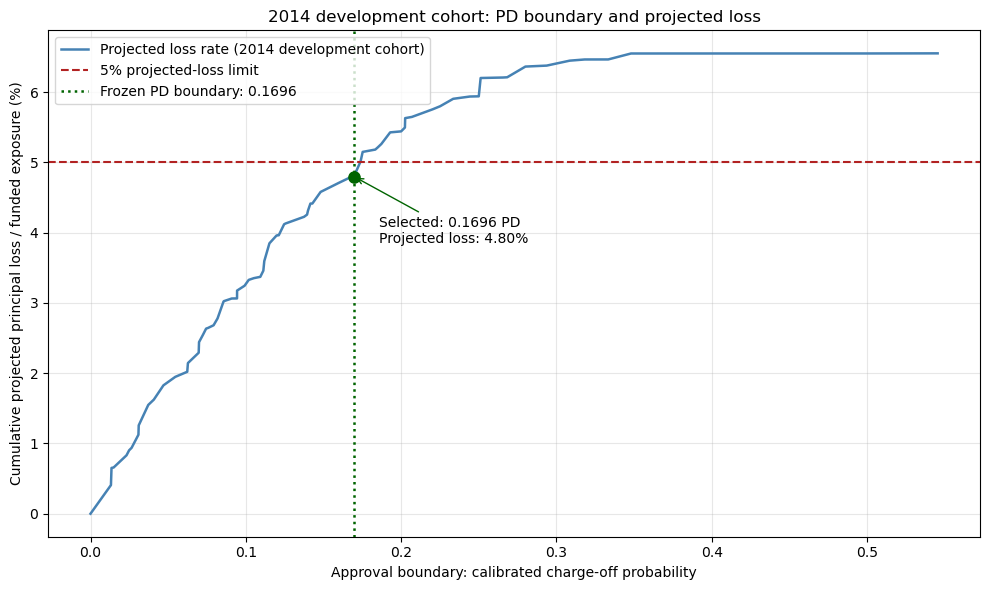

Saved plot: development_policy_curve_2014_unweighted_isotonic.png


In [9]:
# Plot the 2014 development-period policy curve.
# Each point is a distinct calibrated PD boundary; tied loans enter together.

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

curve = policy_curve.sort_values("PD").copy()

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    curve["PD"],
    100 * curve["projected_el_rate"],
    color="steelblue",
    linewidth=1.8,
    label="Projected loss rate (2014 development cohort)",
)

ax.axhline(
    100 * target_loss_rate,
    color="firebrick",
    linestyle="--",
    linewidth=1.5,
    label="5% projected-loss limit",
)

ax.axvline(
    optimal_threshold,
    color="darkgreen",
    linestyle=":",
    linewidth=1.8,
    label=f"Frozen PD boundary: {optimal_threshold:.4f}",
)

ax.scatter(
    [optimal_threshold],
    [100 * selected_policy["projected_el_rate"]],
    color="darkgreen",
    s=65,
    zorder=5,
)

ax.annotate(
    (
        f"Selected: {optimal_threshold:.4f} PD\n"
        f"Projected loss: "
        f"{selected_policy['projected_el_rate']:.2%}"
    ),
    xy=(
        optimal_threshold,
        100 * selected_policy["projected_el_rate"],
    ),
    xytext=(18, -48),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": "darkgreen"},
)

ax.set(
    title="2014 development cohort: PD boundary and projected loss",
    xlabel="Approval boundary: calibrated charge-off probability",
    ylabel="Cumulative projected principal loss / funded exposure (%)",
)

ax.grid(alpha=0.3)
ax.legend(loc="upper left")
fig.tight_layout()

plot_file = (
    figures_dir
    / "development_policy_curve_2014_unweighted_isotonic.png"
)

fig.savefig(plot_file, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved plot: {plot_file.name}")

## Frozen-policy 2015 evaluation

The PD approval boundary was selected on the 2014 development cohort and is applied unchanged to 2015. The projected loss uses calibrated PDs, funded exposure as an origination-exposure proxy, and the LGD assumption estimated from 2011–2014 outcomes. Recorded 2015 charge-off and repayment outcomes are used only for retrospective evaluation.

The accept-all comparison is a descriptive counterfactual over the observed, originated 2015 loans. The difference in realized principal losses equals the realized loss on loans the policy would reject; it is **not** net profit or capital demonstrably preserved, because it omits foregone revenue, funding costs, and changes in which loans would be originated.

In [10]:
# Apply the frozen 2014 policy to the 2015 OOT cohort.
approved_2015 = test_portfolio.loc[
    test_portfolio["PD"].le(optimal_threshold)
].copy()

rejected_2015 = test_portfolio.loc[
    test_portfolio["PD"].gt(optimal_threshold)
].copy()

assert len(approved_2015) + len(rejected_2015) == len(test_portfolio)
assert len(approved_2015) > 0

approved_ead = approved_2015["EAD_proxy"].sum()
approved_expected_loss = approved_2015["Expected_Loss"].sum()
approved_actual_loss = approved_2015["Actual_Loss"].sum()

projected_el_rate = approved_expected_loss / approved_ead
realized_loss_rate = approved_actual_loss / approved_ead

all_ead = test_portfolio["EAD_proxy"].sum()
all_actual_loss = test_portfolio["Actual_Loss"].sum()
all_realized_loss_rate = all_actual_loss / all_ead

rejected_ead = rejected_2015["EAD_proxy"].sum()
rejected_actual_loss = rejected_2015["Actual_Loss"].sum()

# Arithmetic reconciliation of the retrospective comparison.
assert np.isclose(
    all_actual_loss,
    approved_actual_loss + rejected_actual_loss,
)

print("2015 OOT evaluation — frozen 2014 policy")
print(f"PD approval boundary: {optimal_threshold:.6f}")
print(f"Approved loans: {len(approved_2015):,}")
print(f"Rejected loans: {len(rejected_2015):,}")
print(f"Approval rate by loan count: {len(approved_2015) / len(test_portfolio):.2%}")
print(f"Approved funded exposure: ${approved_ead:,.2f}")
print(f"Rejected funded exposure: ${rejected_ead:,.2f}")
print(f"Projected loss on approved loans: ${approved_expected_loss:,.2f}")
print(f"Projected approved-portfolio EL rate: {projected_el_rate:.2%}")
print(f"Realized loss on approved loans: ${approved_actual_loss:,.2f}")
print(f"Realized approved-portfolio loss rate: {realized_loss_rate:.2%}")
print()
print(f"Accept-all funded exposure: ${all_ead:,.2f}")
print(f"Accept-all realized principal loss: ${all_actual_loss:,.2f}")
print(f"Accept-all realized principal-loss rate: {all_realized_loss_rate:.2%}")
print(
    "Retrospective loss difference (accept-all minus approved subset): "
    f"${rejected_actual_loss:,.2f}"
)

2015 OOT evaluation — frozen 2014 policy
PD approval boundary: 0.169611
Approved loans: 195,051
Rejected loans: 87,975
Approval rate by loan count: 68.92%
Approved funded exposure: $2,606,616,000.00
Rejected funded exposure: $1,017,684,800.00
Projected loss on approved loans: $123,750,239.75
Projected approved-portfolio EL rate: 4.75%
Realized loss on approved loans: $137,259,964.31
Realized approved-portfolio loss rate: 5.27%

Accept-all funded exposure: $3,624,300,800.00
Accept-all realized principal loss: $266,899,109.29
Accept-all realized principal-loss rate: 7.36%
Retrospective loss difference (accept-all minus approved subset): $129,639,144.98


## Conclusion: Expected loss and decisions

This notebook combines a calibrated charge-off probability with a historical loss-severity assumption and a simplified origination-exposure proxy. Funded amount is used as the exposure proxy; it is not the measured outstanding balance at the time of charge-off. The mechanical principal-loss fraction uses principal received and recoveries, bounded to [0, 1]. It excludes interest, funding costs, cash-flow timing, and other components of net profitability.

The exposure-weighted LGD assumption was estimated from charged-off loans issued in 2011–2014, without using 2015 outcomes. It was 50.0541%. Among historical charged-off loans, 294 had negative raw loss fractions; bounding these at zero produced an LGD assumption of 50.0541%, versus 50.4015% if those rows were excluded. The reason for those accounting differences was not established.

A 5% **projected** principal-loss-to-funded-exposure limit was applied to the 2014 development cohort. Evaluating distinct calibrated-PD boundaries and treating tied PDs together selected a boundary of 0.169611. It approved 110,226 development-period loans and $1,456,901,700 of funded exposure at a projected loss rate of 4.8002%. The next tied-PD group would raise the projected rate to 5.0163%. Because the isotonic mapping was also fitted on 2014 labels, this development-period policy result is not an independent performance evaluation.

The boundary was then frozen and applied unchanged to the 2015 out-of-time cohort. It approved 195,051 of 283,026 observed loans (68.92%), representing $2,606,616,000 in funded exposure. Projected principal loss on approved loans was $123,750,239.75, or 4.75% of approved exposure. Realized principal loss was $137,259,964.31, or 5.27% of approved exposure. Thus, the projected loss rate was below 5%, but the **realized** rate exceeded 5%; the development-period constraint did not guarantee the realized OOT outcome.

Across all observed 2015 loans, the accept-all benchmark had $3,624,300,800 in funded exposure and $266,899,109.29 in realized principal loss, a rate of 7.36%. The difference between accept-all loss and the approved subset's loss was $129,639,144.98. This is a retrospective principal-loss difference for loans in the observed accepted-loan dataset, **not** demonstrated capital preservation or net profit. The comparison omits foregone interest and fees, funding and operating costs, and the effects of changing which applicants receive loans.

The framework is a historical policy simulation on originated loans. Its charge-off target is a recorded final status rather than default within a fixed horizon, and its exposure and loss measures are simplified proxies. Notebook 06 should use this frozen boundary and these model artifacts when auditing explainability and group-level decision outcomes.